# Độ ổn định theo random seed

Cùng một cấu hình có thể cho điểm khác nhau khi EHO bắt đầu ở những vị trí ngẫu nhiên khác nhau. Notebook thay seed và lặp lại trên Rastrigin 2, 4, 8 và 12 chiều để xem kết quả có ổn định hay không. Hình lưu sẵn dùng 25 seed của chế độ FULL.

In [1]:
from experiment_helpers.artifacts import save_experiment_artifacts

import os
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from eho import EHOConfig
from objectives import rastrigin
from experiment_helpers.runner import (
    assert_reproducible, compare_configurations, results_frame, seeds_for,
)
from experiment_helpers.statistics import summarize_experiment_results

MODE = os.getenv("EHO_EXPERIMENT_MODE", "QUICK").upper()
seeds = seeds_for(MODE)
base = EHOConfig(population_size=20, max_generations=50)
print(MODE, seeds)
print(base)
assert_reproducible(rastrigin, base, seeds[0])
print("Kiểm tra tái lập cùng seed đã đạt.")

FULL [101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125]
EHOConfig(population_size=20, dimension=4, alpha=0.5, beta=0.1, max_generations=50, lower_bounds=(-5.12, -5.12, -5.12, -5.12), upper_bounds=(5.12, 5.12, 5.12, 5.12), random_seed=42)
Kiểm tra tái lập cùng seed đã đạt.


,runs,minimum,mean,median,maximum,std,variance,seconds,evaluations,feasible_rate,violations,target_rate,mean_per_dimension
group,,,,,,,,,,,,,
2D,25,2.892075e-09,0.000002,2.748412e-07,0.000026,0.000005,3.006571e-11,0.015286,1020.0,1.0,9.12,1.00,8.971071e-07
4D,25,1.689830e-05,0.000513,3.590389e-04,0.002255,0.000526,2.769456e-07,0.015258,1020.0,1.0,17.52,0.88,1.282548e-04
8D,25,2.020276e-03,0.008226,7.055620e-03,0.015881,0.004306,1.854375e-05,0.015645,1020.0,1.0,38.08,0.00,1.028191e-03
12D,25,7.649658e-03,0.020112,1.757015e-02,0.047253,0.010477,1.097639e-04,0.015517,1020.0,1.0,52.96,0.00,1.675984e-03


,group,seed,absolute_error,best_in_bounds,violating_coordinates
0,2D,101,4.193630e-07,True,17
1,2D,102,1.619367e-06,True,7
2,2D,103,4.807104e-09,True,7
3,2D,104,1.988344e-07,True,12
4,2D,105,1.697877e-08,True,10
...,...,...,...,...,...
95,12D,121,4.725254e-02,True,44
96,12D,122,1.471240e-02,True,59
97,12D,123,9.306261e-03,True,57
98,12D,124,9.466909e-03,True,58


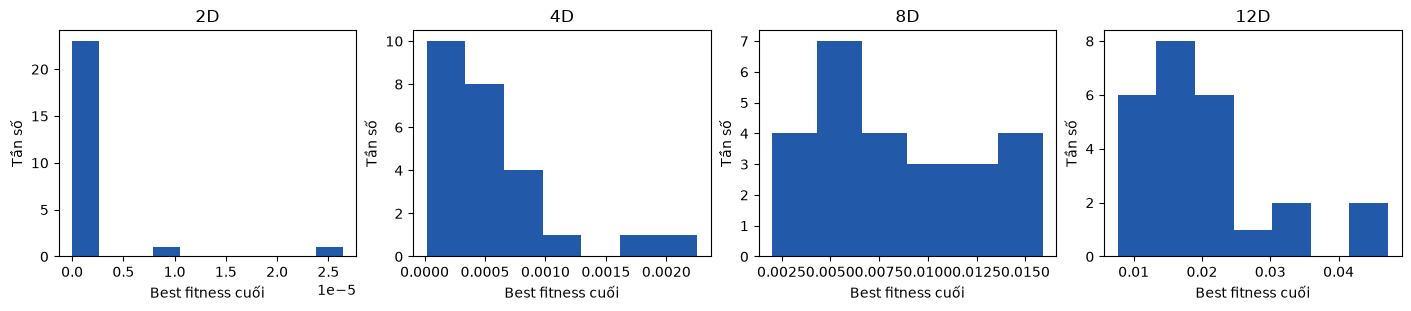

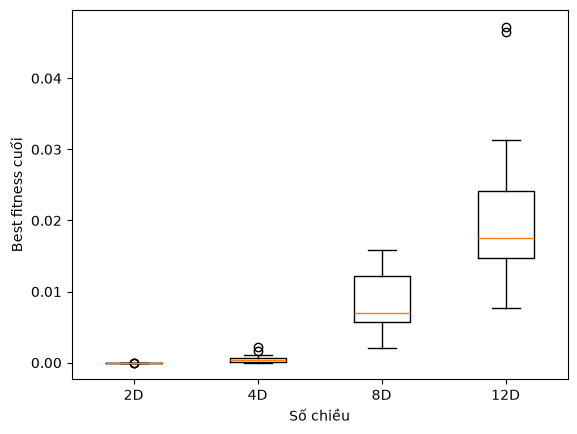

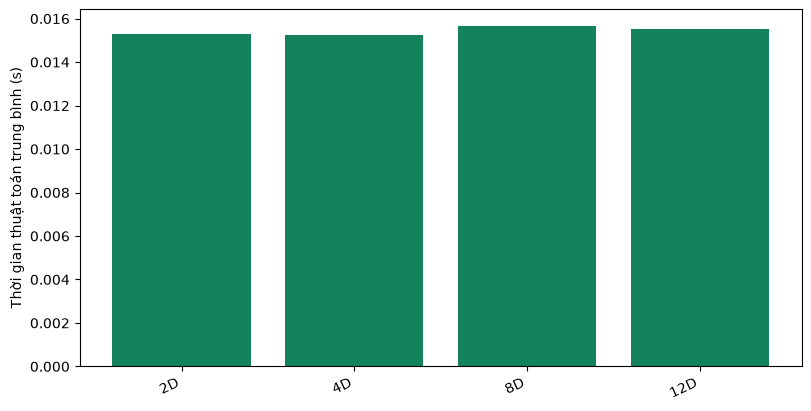

In [2]:
from experiment_helpers.plotting import plot_fitness_distribution, plot_runtime_comparison

configs = {f"{dimension}D": EHOConfig(dimension=dimension, population_size=20, max_generations=50)
           for dimension in (2, 4, 8, 12)}
groups = compare_configurations(rastrigin, configs, seeds)
frame = results_frame(groups)
frame["absolute_error"] = frame["fitness"].abs()
frame["fitness_per_dimension"] = frame["fitness"] / frame["dimension"]
tolerance = 1e-3
summary = summarize_experiment_results(frame, tolerance)
summary["mean_per_dimension"] = frame.groupby("group")["fitness_per_dimension"].mean()
display(summary)
display(frame[["group", "seed", "absolute_error", "best_in_bounds", "violating_coordinates"]])
plot_fitness_distribution(frame)
_, axis = plt.subplots()
axis.boxplot([frame.loc[frame.group == label, "fitness"] for label in configs])
axis.set_xticks(range(1, len(configs) + 1), list(configs))
axis.set(xlabel="Số chiều", ylabel="Best fitness cuối")
plot_runtime_comparison(summary)
save_experiment_artifacts("experiment-3", "stability", MODE, seeds, frame, summary)
plt.show()

## Cách đọc và kết luận

**Histogram** đếm số lần chạy rơi vào mỗi khoảng điểm. **Boxplot** tóm tắt các lần chạy bằng một hộp. Vạch giữa là median, tức mức điểm đứng giữa khi sắp các kết quả từ thấp đến cao. Hộp chứa 50% kết quả ở giữa. Các chấm nằm xa hộp vẫn được tính vào thống kê.

Trong bảng, `target_rate` là phần lần chạy đạt điểm từ 0,001 trở xuống. `feasible_rate` là phần lần chạy có nghiệm tốt nhất nằm trong giới hạn tọa độ. Đây là hai câu hỏi riêng. `mean_per_dimension` chia điểm trung bình cho số chiều để dễ đọc hơn khi so sánh các bài Rastrigin có số tọa độ khác nhau.

In [3]:
print("SD mẫu theo nhóm:")
print(summary["std"].to_string())
print(f"Nhóm có mean thấp nhất: {summary['mean'].idxmin()}; SD thấp nhất: {summary['std'].idxmin()}.")
print(f"Thời gian trung bình nằm trong [{summary.seconds.min():.4f}, {summary.seconds.max():.4f}] giây.")
print("Kết luận chỉ áp dụng cho cấu hình, ngân sách và tập seed trong bảng.")

SD mẫu theo nhóm:
group
2D     0.000005
4D     0.000526
8D     0.004306
12D    0.010477
Nhóm có mean thấp nhất: 2D; SD thấp nhất: 2D.
Thời gian trung bình nằm trong [0.0153, 0.0156] giây.
Kết luận chỉ áp dụng cho cấu hình, ngân sách và tập seed trong bảng.
